# **Download File**

In [5]:
!kaggle datasets download aleksandrpikul222/nuaaaa

Dataset URL: https://www.kaggle.com/datasets/aleksandrpikul222/nuaaaa
License(s): apache-2.0
 99% 377M/381M [00:05<00:00, 73.2MB/s]
100% 381M/381M [00:05<00:00, 72.6MB/s]


In [6]:
!unzip /content/nuaaaa.zip

Streaming output truncated to the last 5000 lines.
  inflating: raw/ImposterRaw/0005/0005_00_00_01_98.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_0.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_116.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_134.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_152.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_170.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_189.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_206.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_224.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_246.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_264.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_283.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_300.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_319.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_337.jpg  
  inflating: raw/ImposterRaw/0005/0005_00_01_02_355.jpg  
  inflating: raw/Imposte

In [7]:
!kaggle datasets download mdhasibulhossain231/face-anti-spoofing-large-dataset-image-video

Dataset URL: https://www.kaggle.com/datasets/mdhasibulhossain231/face-anti-spoofing-large-dataset-image-video
License(s): MIT
100% 13.9G/13.9G [03:08<00:00, 146MB/s]
100% 13.9G/13.9G [03:08<00:00, 79.0MB/s]


In [8]:
!unzip /content/face-anti-spoofing-large-dataset-image-video.zip

Streaming output truncated to the last 5000 lines.
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id0_s2_105.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id0_s2_135.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id0_s2_15.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id0_s2_150.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id0_s2_60.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id0_s2_90.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id12_s0_120.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id12_s0_150.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id12_s0_45.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id12_s0_60.png  
  inflating: 1 Image Dataset/Spoof icc_fasd/FT720P_IIYAMAXB_SMG955U_id12_s0_75.png  
  inflating: 1 

In [9]:
import os
import shutil
from pathlib import Path
from tqdm import tqdm

# =====================================
# 1. KONFIGURASI PATH
# =====================================

SOURCE = Path("/content")

NUAA = SOURCE / "raw"
LARGE = SOURCE / "1 Image Dataset"

OUTPUT = Path("Face_Anti_Spoofing_Dataset")

# Ekstensi gambar yang diterima
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# =====================================
# 2. MEMBUAT STRUKTUR FOLDER
# =====================================

folders = [
    OUTPUT / "Real" / "NUAA",
    OUTPUT / "Real" / "Large_Dataset",
    OUTPUT / "Print" / "NUAA",
    OUTPUT / "Digital_Screen_Spoof" / "Large_Dataset"
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# =====================================
# 3. FUNGSI MENYALIN GAMBAR
# =====================================

def copy_images(source_folder, destination_folder, prefix):
    source_folder = Path(source_folder)
    destination_folder = Path(destination_folder)

    images = [
        file for file in source_folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    copied = 0

    for index, image in enumerate(
        tqdm(images, desc=f"Copying {prefix}")
    ):
        # Nama file unik untuk mencegah bentrok
        new_name = f"{prefix}_{index:06d}{image.suffix.lower()}"

        destination = destination_folder / new_name

        shutil.copy2(image, destination)
        copied += 1

    return copied

# =====================================
# 4. PEMETAAN DATASET
# =====================================

tasks = [
    # NUAA
    (NUAA / "ClientRaw",
     OUTPUT / "Real" / "NUAA", "nuaa_real"),

    (NUAA / "ImposterRaw",
     OUTPUT / "Print" / "NUAA", "nuaa_print"),

    # Large Dataset
    (LARGE / "Real",
     OUTPUT / "Real" / "Large_Dataset", "large_real"),

    (LARGE / "Real icc_fasd",
     OUTPUT / "Real" / "Large_Dataset", "large_real_icc"),

    (LARGE / "Spoof",
     OUTPUT / "Digital_Screen_Spoof" / "Large_Dataset",
     "large_spoof"),

    (LARGE / "Spoof icc_fasd",
     OUTPUT / "Digital_Screen_Spoof" / "Large_Dataset",
     "large_spoof_icc")
]

# =====================================
# 5. PROSES PENGGABUNGAN
# =====================================

total = 0

for source, destination, prefix in tasks:

    if not source.exists():
        print(f"[WARNING] Folder tidak ditemukan: {source}")
        continue

    count = copy_images(source, destination, prefix)

    print(f"{prefix}: {count} gambar")
    total += count

# =====================================
# 6. RINGKASAN HASIL
# =====================================

print("\n========== DATASET SUMMARY ==========")

for class_name in [
    "Real", "Print", "Digital_Screen_Spoof"
]:
    class_path = OUTPUT / class_name

    count = sum(
        1 for file in class_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{class_name}: {count} gambar")

print("------------------------------------")
print(f"Total gambar: {total}")
print(f"Output: {OUTPUT.resolve()}")


Copying nuaa_real: 100%|██████████| 5105/5105 [00:03<00:00, 1276.87it/s]


nuaa_real: 5105 gambar


Copying nuaa_print: 100%|██████████| 7509/7509 [00:05<00:00, 1287.90it/s]


nuaa_print: 7509 gambar


Copying large_real: 100%|██████████| 391/391 [00:02<00:00, 131.76it/s]


large_real: 391 gambar


... (2 outputs left out)

Copying large_spoof: 100%|██████████| 812/812 [00:01<00:00, 456.37it/s]


large_spoof: 812 gambar


Copying large_spoof_icc: 100%|██████████| 3468/3468 [00:08<00:00, 416.79it/s]


large_spoof_icc: 3468 gambar

========== DATASET SUMMARY ==========
Real: 8937 gambar
Print: 7509 gambar
Digital_Screen_Spoof: 4280 gambar
------------------------------------
Total gambar: 20726
Output: /content/Face_Anti_Spoofing_Dataset


# **Configuration**

In [10]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
# ==========================================
# 2. EXPERIMENT CONFIGURATION
# ==========================================

DATASET_DIR = "/content/Face_Anti_Spoofing_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.001
DROPOUT_RATE = 0.3

NUM_CLASSES = 3
SEED = 42

CLASS_NAMES = [
    "Real",
    "Print",
    "Digital_Screen_Spoof"
]

CLASS_LABELS = {
    "Real": 0,
    "Print": 1,
    "Digital_Screen_Spoof": 2
}

print("Experiment: Scenario 1")
print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Dropout:", DROPOUT_RATE)

Experiment: Scenario 1
Image Size: (224, 224)
Batch Size: 32
Epochs: 10
Learning Rate: 0.001
Dropout: 0.3


In [12]:
# ==========================================
# 3. CHECK DATASET
# ==========================================

for class_name in CLASS_NAMES:

    class_path = os.path.join(DATASET_DIR, class_name)

    total_images = 0

    for root, dirs, files in os.walk(class_path):
        total_images += sum(
            file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
            for file in files
        )

    print(f"{class_name}: {total_images} images")

Real: 8937 images
Print: 7509 images
Digital_Screen_Spoof: 4280 images


# **Splitting Data**

In [13]:
import os
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

DATASET_DIR = "/content/Face_Anti_Spoofing_Dataset"

CLASS_LABELS = {
    "Real": 0,
    "Print": 1,
    "Digital_Screen_Spoof": 2
}

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

data = []

for class_name, label in CLASS_LABELS.items():

    class_dir = Path(DATASET_DIR) / class_name

    for image_path in class_dir.rglob("*"):

        if image_path.suffix.lower() in image_extensions:

            data.append({
                "image_path": str(image_path),
                "label": label,
                "class_name": class_name
            })

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nClass distribution:")
print(df["class_name"].value_counts())


Total images: 20726

Class distribution:
class_name
Real                    8937
Print                   7509
Digital_Screen_Spoof    4280
Name: count, dtype: int64


In [14]:
# Split 70% training dan 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Split temporary menjadi 15% validation dan 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training: 14508
Validation: 3109
Testing: 3109

Total: 20726


In [15]:
for name, subset in [
    ("TRAINING", train_df),
    ("VALIDATION", val_df),
    ("TESTING", test_df)
]:

    print(f"\n{name}")
    print(subset["class_name"].value_counts().sort_index())


TRAINING
class_name
Digital_Screen_Spoof    2996
Print                   5256
Real                    6256
Name: count, dtype: int64

VALIDATION
class_name
Digital_Screen_Spoof     642
Print                   1127
Real                    1340
Name: count, dtype: int64

TESTING
class_name
Digital_Screen_Spoof     642
Print                   1126
Real                    1341
Name: count, dtype: int64


# **Preprocessing**

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pathlib import Path

In [24]:
# ==========================================
# IMPROVED HAAR CASCADE
# ==========================================

cascade_default = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

cascade_alt2 = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_alt2.xml"
)


def detect_and_crop_face(image_path, margin=0.30):

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Improve image contrast
    gray = cv2.equalizeHist(gray)

    # Try first classifier
    faces = cascade_default.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(30, 30)
    )

    # Try second classifier if first fails
    if len(faces) == 0:

        faces = cascade_alt2.detectMultiScale(
            gray,
            scaleFactor=1.05,
            minNeighbors=3,
            minSize=(30, 30)
        )

    if len(faces) == 0:
        return None

    # Select largest detected face
    x, y, w, h = max(
        faces,
        key=lambda face: face[2] * face[3]
    )

    # Add 30% margin
    margin_x = int(w * margin)
    margin_y = int(h * margin)

    x1 = max(0, x - margin_x)
    y1 = max(0, y - margin_y)

    x2 = min(image.shape[1], x + w + margin_x)
    y2 = min(image.shape[0], y + h + margin_y)

    # Crop face
    face_crop = image[y1:y2, x1:x2]

    # BGR to RGB
    face_crop = cv2.cvtColor(
        face_crop,
        cv2.COLOR_BGR2RGB
    )

    # Resize to 224x224
    face_crop = cv2.resize(
        face_crop,
        (224, 224)
    )

    return face_crop


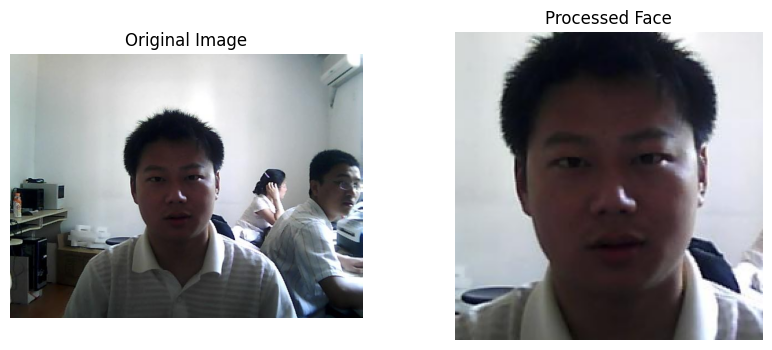

In [25]:

sample_path = train_df.iloc[0]["image_path"]

original = cv2.imread(sample_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

processed = detect_and_crop_face(sample_path)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)

if processed is not None:
    plt.imshow(processed)
    plt.title("Processed Face")
else:
    plt.title("Face Not Detected")

plt.axis("off")
plt.show()


In [26]:
import os
import cv2
import pandas as pd
from tqdm.auto import tqdm

# ==========================================
# 1. OUTPUT DIRECTORY
# ==========================================

OUTPUT_DIR = "/content/Face_Anti_Spoofing_Processed"

# ==========================================
# 2. PREPROCESSING FUNCTION
# ==========================================

def preprocess_dataset(dataframe, split_name):

    success_count = 0
    failed_images = []

    for idx, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc=f"Processing {split_name}"
    ):

        image_path = row["image_path"]
        class_name = row["class_name"]

        # Face detection and cropping
        processed = detect_and_crop_face(image_path)

        if processed is None:

            failed_images.append({
                "image_path": image_path,
                "class_name": class_name,
                "split": split_name
            })

            continue

        # Create output folder
        save_dir = os.path.join(
            OUTPUT_DIR,
            split_name,
            class_name
        )

        os.makedirs(save_dir, exist_ok=True)

        # Unique filename
        filename = f"{idx}_{os.path.basename(image_path)}"

        save_path = os.path.join(save_dir, filename)

        # RGB to BGR for OpenCV saving
        processed_bgr = cv2.cvtColor(
            processed,
            cv2.COLOR_RGB2BGR
        )

        cv2.imwrite(save_path, processed_bgr)

        success_count += 1

    print(f"\n{split_name} Results")
    print("Successfully processed:", success_count)
    print("Failed:", len(failed_images))

    return failed_images


# ==========================================
# 3. PROCESS ALL DATA SPLITS
# ==========================================

failed_images = []

failed_images += preprocess_dataset(train_df, "train")
failed_images += preprocess_dataset(val_df, "validation")
failed_images += preprocess_dataset(test_df, "test")


# ==========================================
# 4. SAVE FAILED IMAGE LOG
# ==========================================

failed_df = pd.DataFrame(failed_images)

failed_df.to_csv(
    os.path.join(OUTPUT_DIR, "failed_images.csv"),
    index=False
)

print("\nTotal failed images:", len(failed_df))
print("Preprocessing completed!")


Processing train:   0%|          | 0/14508 [00:00<?, ?it/s]


train Results
Successfully processed: 14432
Failed: 76


Processing validation:   0%|          | 0/3109 [00:00<?, ?it/s]


validation Results
Successfully processed: 3101
Failed: 8


Processing test:   0%|          | 0/3109 [00:00<?, ?it/s]


test Results
Successfully processed: 3094
Failed: 15

Total failed images: 99
Preprocessing completed!


In [27]:

import os
import pandas as pd

OUTPUT_DIR = "/content/Face_Anti_Spoofing_Processed"

splits = ["train", "validation", "test"]
classes = ["Real", "Print", "Digital_Screen_Spoof"]

results = []

for split in splits:
    for class_name in classes:

        folder = os.path.join(
            OUTPUT_DIR, split, class_name
        )

        count = 0

        if os.path.exists(folder):
            count = sum(
                file.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
                for file in os.listdir(folder)
            )

        results.append({
            "Split": split,
            "Class": class_name,
            "Processed Images": count
        })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print("\nTotal processed:",
      results_df["Processed Images"].sum())

print("\nTotal failed:",
      len(failed_images))


     Split                Class  Processed Images
     train                 Real              6244
     train                Print              5249
     train Digital_Screen_Spoof              2939
validation                 Real              1339
validation                Print              1124
validation Digital_Screen_Spoof               638
      test                 Real              1339
      test                Print              1123
      test Digital_Screen_Spoof               632

Total processed: 20627

Total failed: 99


In [29]:
import os
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

PyTorch Version: 2.14.1+cu130
GPU Available: True


In [30]:
# ==========================================
# TRANSFORMATIONS
# ==========================================

# Augmentation for training
train_augmentation = [
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2)
]

# Custom CNN normalization
cnn_train_transform = transforms.Compose(
    train_augmentation + [
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.5, 0.5, 0.5],
            std=[0.5, 0.5, 0.5]
        )
    ]
)

cnn_eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# ResNet18 ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

resnet_train_transform = transforms.Compose(
    train_augmentation + [
        transforms.ToTensor(),
        transforms.Normalize(
            mean=imagenet_mean,
            std=imagenet_std
        )
    ]
)

resnet_eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

In [31]:
# ==========================================
# CUSTOM PYTORCH DATASET
# ==========================================

class FaceAntiSpoofDataset(Dataset):

    def __init__(self, root_dir, transform=None):

        self.root_dir = root_dir
        self.transform = transform

        self.class_labels = {
            "Real": 0,
            "Print": 1,
            "Digital_Screen_Spoof": 2
        }

        self.samples = []

        for class_name, label in self.class_labels.items():

            class_dir = os.path.join(root_dir, class_name)

            for filename in os.listdir(class_dir):

                if filename.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                ):

                    image_path = os.path.join(class_dir, filename)

                    self.samples.append((image_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [32]:
# ==========================================
# DATASET CONFIGURATION
# ==========================================

OUTPUT_DIR = "/content/Face_Anti_Spoofing_Processed"

BATCH_SIZE = 32

# ==========================================
# CREATE DATALOADERS
# ==========================================

def create_dataloaders(train_transform, eval_transform):

    train_dataset = FaceAntiSpoofDataset(
        os.path.join(OUTPUT_DIR, "train"),
        transform=train_transform
    )

    val_dataset = FaceAntiSpoofDataset(
        os.path.join(OUTPUT_DIR, "validation"),
        transform=eval_transform
    )

    test_dataset = FaceAntiSpoofDataset(
        os.path.join(OUTPUT_DIR, "test"),
        transform=eval_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader, test_loader


# Custom CNN
cnn_train_loader, cnn_val_loader, cnn_test_loader = (
    create_dataloaders(
        cnn_train_transform,
        cnn_eval_transform
    )
)

# ResNet18
resnet_train_loader, resnet_val_loader, resnet_test_loader = (
    create_dataloaders(
        resnet_train_transform,
        resnet_eval_transform
    )
)

print("DataLoaders successfully created!")

DataLoaders successfully created!


In [33]:
# ==========================================
# CHECK DATA BATCH
# ==========================================

images, labels = next(iter(cnn_train_loader))

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)

print("Labels:", labels[:10].tolist())

print("\nLabel Mapping:")
print("Real = 0")
print("Print = 1")
print("Digital Screen Spoof = 2")

Image Shape: torch.Size([32, 3, 224, 224])
Label Shape: torch.Size([32])
Labels: [1, 1, 1, 0, 2, 0, 1, 0, 0, 1]

Label Mapping:
Real = 0
Print = 1
Digital Screen Spoof = 2


# **Training**

In [35]:

import torch
import torch.nn as nn

# ==========================================
# CUSTOM CNN ARCHITECTURE
# ==========================================

class CustomCNN(nn.Module):

    def __init__(self, num_classes=3, dropout=0.3):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x


# ==========================================
# INITIALIZE MODEL
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

cnn_model = CustomCNN(
    num_classes=3,
    dropout=0.3
).to(device)

print(cnn_model)
print("\nDevice:", device)


CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d

In [36]:

# ==========================================
# TEST CNN MODEL
# ==========================================

dummy_input = torch.randn(32, 3, 224, 224).to(device)

with torch.no_grad():
    output = cnn_model(dummy_input)

print("Input Shape:", dummy_input.shape)
print("Output Shape:", output.shape)

total_params = sum(
    p.numel() for p in cnn_model.parameters()
)

trainable_params = sum(
    p.numel() for p in cnn_model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)


Input Shape: torch.Size([32, 3, 224, 224])
Output Shape: torch.Size([32, 3])
Total Parameters: 390147
Trainable Parameters: 390147


In [37]:

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights

# ==========================================
# RESNET18 PRETRAINED IMAGENET
# ==========================================

class ResNet18Model(nn.Module):

    def __init__(self, num_classes=3, dropout=0.3):

        super(ResNet18Model, self).__init__()

        # Load pretrained ResNet18
        self.model = models.resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        # Freeze backbone
        for param in self.model.parameters():
            param.requires_grad = False

        # Replace classification layer
        in_features = self.model.fc.in_features

        self.model.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)


# ==========================================
# INITIALIZE MODEL
# ==========================================

resnet_model = ResNet18Model(
    num_classes=3,
    dropout=0.3
).to(device)

print(resnet_model)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 99.6MB/s]


ResNet18Model(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05,

In [38]:

total_params = sum(
    p.numel() for p in resnet_model.parameters()
)

trainable_params = sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Frozen Parameters:", total_params - trainable_params)


Total Parameters: 11178051
Trainable Parameters: 1539
Frozen Parameters: 11176512


In [39]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

from tqdm.auto import tqdm

# Experiment configuration
LEARNING_RATE = 0.001
EPOCHS = 10

criterion = nn.CrossEntropyLoss()

print("Training Configuration Loaded")
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Device:", device)

Training Configuration Loaded
Learning Rate: 0.001
Epochs: 10
Device: cuda


In [40]:

# ==========================================
# TRAINING FUNCTION
# ==========================================

def train_model(model, train_loader, val_loader, model_name):

    # Optimizer only updates trainable parameters
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "epoch_time": []
    }

    best_val_loss = float("inf")
    best_model_weights = copy.deepcopy(model.state_dict())

    print(f"\nStarting Training: {model_name}")

    for epoch in range(EPOCHS):

        start_time = time.time()

        # ==================================
        # TRAINING
        # ==================================

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"
        ):

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        # ==================================
        # VALIDATION
        # ==================================

        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in tqdm(
                val_loader,
                desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"
            ):

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_running_loss / val_total
        val_accuracy = val_correct / val_total

        epoch_time = time.time() - start_time

        # Save history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)
        history["epoch_time"].append(epoch_time)

        # Save best model based on validation loss
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

        print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Val Loss: {val_loss:.4f}")
        print(f"Train Accuracy: {train_accuracy:.4f}")
        print(f"Val Accuracy: {val_accuracy:.4f}")
        print(f"Epoch Time: {epoch_time:.2f} seconds")

    # Restore best model weights
    model.load_state_dict(best_model_weights)

    # Save best checkpoint
    os.makedirs("/content/model_checkpoints", exist_ok=True)

    checkpoint_path = (
        f"/content/model_checkpoints/{model_name}_best.pth"
    )

    torch.save(model.state_dict(), checkpoint_path)

    print(f"\nBest Validation Loss: {best_val_loss:.4f}")
    print("Model saved:", checkpoint_path)

    return model, history

In [41]:
# ==========================================
# TRAIN CUSTOM CNN
# ==========================================

cnn_model, cnn_history = train_model(
    model=cnn_model,
    train_loader=cnn_train_loader,
    val_loader=cnn_val_loader,
    model_name="CustomCNN"
)


Starting Training: CustomCNN


Epoch 1/10 [Train]:   0%|          | 0/451 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/97 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1638, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del_


Epoch [1/10]
Train Loss: 0.3992
Val Loss: 0.2493
Train Accuracy: 0.8468
Val Accuracy: 0.9097
Epoch Time: 66.03 seconds


Epoch 2/10 [Train]:   0%|          | 0/451 [00:00<?, ?it/s]

... (30 outputs left out)

Epoch 10/10 [Train]:   0%|          | 0/451 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
    assert self._parent_pid == os.getpid(), 'can only test a child process'Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
AssertionError    : self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored 

Epoch 10/10 [Val]:   0%|          | 0/97 [00:00<?, ?it/s]


Epoch [10/10]
Train Loss: 0.1263
Val Loss: 0.1404
Train Accuracy: 0.9540
Val Accuracy: 0.9539
Epoch Time: 60.61 seconds

Best Validation Loss: 0.0861
Model saved: /content/model_checkpoints/CustomCNN_best.pth


In [42]:
# ==========================================
# TRAIN RESNET18
# ==========================================

resnet_model, resnet_history = train_model(
    model=resnet_model,
    train_loader=resnet_train_loader,
    val_loader=resnet_val_loader,
    model_name="ResNet18"
)


Starting Training: ResNet18


Epoch 1/10 [Train]:   0%|          | 0/451 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 1/10 [Val]:   0%|          | 0/97 [00:00<?, ?it/s]


Epoch [1/10]
Train Loss: 0.4206
Val Loss: 0.2384
Train Accuracy: 0.8419
Val Accuracy: 0.9126
Epoch Time: 58.57 seconds


Epoch 2/10 [Train]:   0%|          | 0/451 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 10/10 [Train]:   0%|          | 0/451 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb411f6bf60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 [Val]:   0%|          | 0/97 [00:00<?, ?it/s]


Epoch [10/10]
Train Loss: 0.2582
Val Loss: 0.1332
Train Accuracy: 0.8982
Val Accuracy: 0.9487
Epoch Time: 56.63 seconds

Best Validation Loss: 0.1332
Model saved: /content/model_checkpoints/ResNet18_best.pth


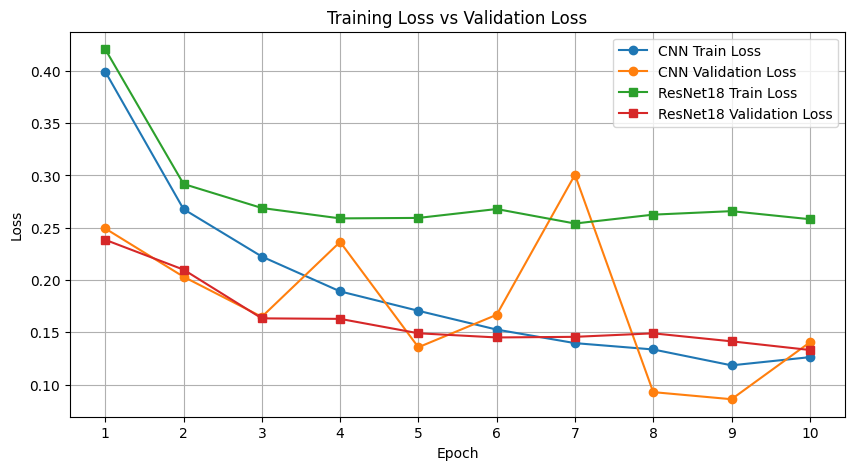

In [43]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))

# Custom CNN
plt.plot(
    epochs,
    cnn_history["train_loss"],
    marker="o",
    label="CNN Train Loss"
)

plt.plot(
    epochs,
    cnn_history["val_loss"],
    marker="o",
    label="CNN Validation Loss"
)

# ResNet18
plt.plot(
    epochs,
    resnet_history["train_loss"],
    marker="s",
    label="ResNet18 Train Loss"
)

plt.plot(
    epochs,
    resnet_history["val_loss"],
    marker="s",
    label="ResNet18 Validation Loss"
)

plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()


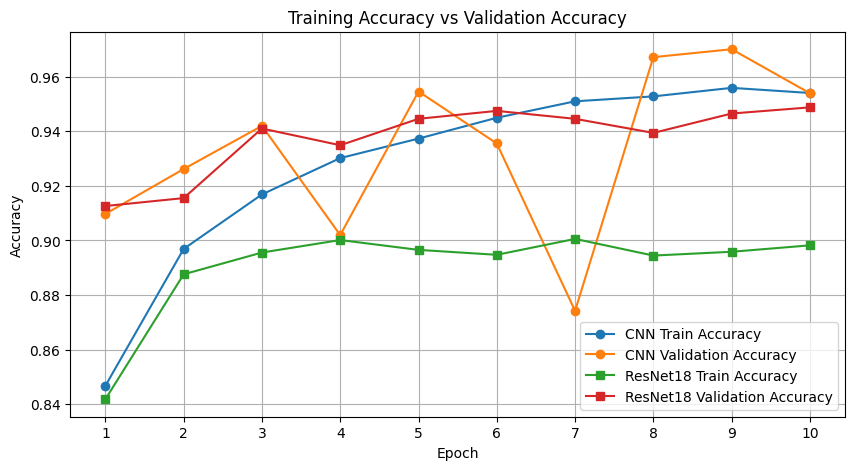

In [44]:

plt.figure(figsize=(10, 5))

# Custom CNN
plt.plot(
    epochs,
    cnn_history["train_accuracy"],
    marker="o",
    label="CNN Train Accuracy"
)

plt.plot(
    epochs,
    cnn_history["val_accuracy"],
    marker="o",
    label="CNN Validation Accuracy"
)

# ResNet18
plt.plot(
    epochs,
    resnet_history["train_accuracy"],
    marker="s",
    label="ResNet18 Train Accuracy"
)

plt.plot(
    epochs,
    resnet_history["val_accuracy"],
    marker="s",
    label="ResNet18 Validation Accuracy"
)

plt.title("Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()

In [45]:

def get_training_summary(history, model_name):

    best_epoch = (
        history["val_loss"].index(
            min(history["val_loss"])
        ) + 1
    )

    return {
        "Model": model_name,
        "Best Epoch": best_epoch,
        "Train Loss": history["train_loss"][best_epoch - 1],
        "Val Loss": history["val_loss"][best_epoch - 1],
        "Train Accuracy": history["train_accuracy"][best_epoch - 1],
        "Val Accuracy": history["val_accuracy"][best_epoch - 1],
        "Average Epoch Time (s)": sum(history["epoch_time"]) / len(history["epoch_time"])
    }


summary = pd.DataFrame([
    get_training_summary(cnn_history, "Custom CNN"),
    get_training_summary(resnet_history, "ResNet18")
])

display(summary.round(4))

,Model,Best Epoch,Train Loss,Val Loss,Train Accuracy,Val Accuracy,Average Epoch Time (s)
0,Custom CNN,9,0.1185,0.0861,0.9559,0.9700,61.6105
1,ResNet18,10,0.2582,0.1332,0.8982,0.9487,56.2170


# **Evaluation**

In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import numpy as np

In [47]:

def evaluate_model(model, test_loader, model_name):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in tqdm(
            test_loader,
            desc=f"Testing {model_name}"
        ):

            images = images.to(device)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    # Calculate metrics
    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    print(f"\n===== {model_name} Evaluation =====")

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            all_labels,
            all_predictions,
            labels=[0, 1, 2],
            target_names=[
                "Real",
                "Print",
                "Digital Screen Spoof"
            ],
            zero_division=0
        )
    )

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "y_true": all_labels,
        "y_pred": all_predictions
    }


In [48]:

cnn_results = evaluate_model(
    model=cnn_model,
    test_loader=cnn_test_loader,
    model_name="Custom CNN"
)


Testing Custom CNN:   0%|          | 0/97 [00:00<?, ?it/s]


===== Custom CNN Evaluation =====
Accuracy : 0.9664
Precision: 0.9554
Recall   : 0.9674
F1-Score : 0.9607

Classification Report:
                      precision    recall  f1-score   support

                Real       0.98      0.95      0.96      1339
               Print       1.00      0.99      0.99      1123
Digital Screen Spoof       0.89      0.97      0.92       632

            accuracy                           0.97      3094
           macro avg       0.96      0.97      0.96      3094
        weighted avg       0.97      0.97      0.97      3094



In [49]:

resnet_results = evaluate_model(
    model=resnet_model,
    test_loader=resnet_test_loader,
    model_name="ResNet18"
)


Testing ResNet18:   0%|          | 0/97 [00:00<?, ?it/s]


===== ResNet18 Evaluation =====
Accuracy : 0.9470
Precision: 0.9439
Recall   : 0.9293
F1-Score : 0.9358

Classification Report:
                      precision    recall  f1-score   support

                Real       0.92      0.96      0.94      1339
               Print       0.99      0.99      0.99      1123
Digital Screen Spoof       0.92      0.83      0.87       632

            accuracy                           0.95      3094
           macro avg       0.94      0.93      0.94      3094
        weighted avg       0.95      0.95      0.95      3094



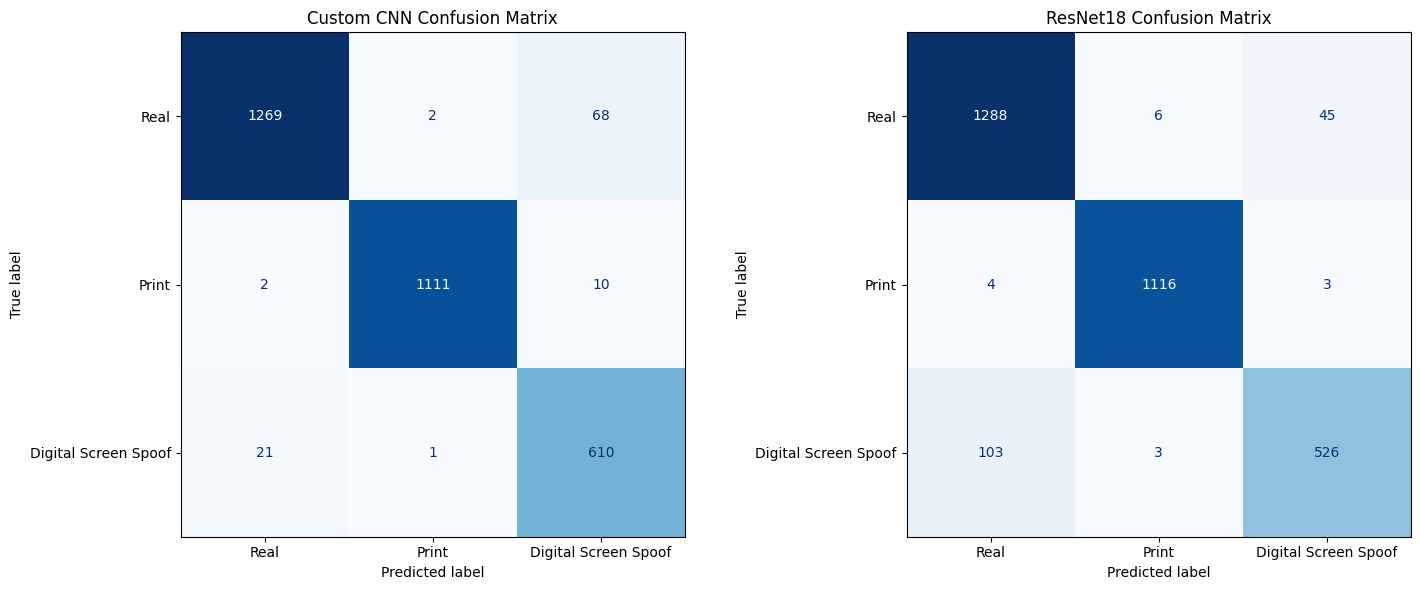

In [50]:
class_names = [
    "Real",
    "Print",
    "Digital Screen Spoof"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

results_list = [
    (cnn_results, axes[0]),
    (resnet_results, axes[1])
]

for results, ax in results_list:

    cm = confusion_matrix(
        results["y_true"],
        results["y_pred"],
        labels=[0, 1, 2]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f'{results["model"]} Confusion Matrix')

plt.tight_layout()
plt.show()


In [51]:

final_comparison = pd.DataFrame([
    {
        "Model": cnn_results["model"],
        "Accuracy": cnn_results["accuracy"],
        "Precision": cnn_results["precision"],
        "Recall": cnn_results["recall"],
        "F1-Score": cnn_results["f1_score"]
    },
    {
        "Model": resnet_results["model"],
        "Accuracy": resnet_results["accuracy"],
        "Precision": resnet_results["precision"],
        "Recall": resnet_results["recall"],
        "F1-Score": resnet_results["f1_score"]
    }
])

display(final_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Custom CNN,0.9664,0.9554,0.9674,0.9607
1,ResNet18,0.9470,0.9439,0.9293,0.9358


In [52]:

from google.colab import files

files.download(
    "/content/model_checkpoints/CustomCNN_best.pth"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
# Download ResNet18
files.download(
    "/content/model_checkpoints/ResNet18_best.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>